In [10]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from xgboost import XGBClassifier

In [14]:
data=load_breast_cancer()
X=pd.DataFrame(data.data, columns=data.feature_names)
y=pd.Series(data.target)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42, stratify=y)

In [21]:
#Deafult XGBoost Model
model=XGBClassifier(
    n_estimetors=100,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [01:52:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimetors" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_estimetors=100,
              n_jobs=None, ...)

In [22]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9473684210526315
              precision    recall  f1-score   support

           0       0.95      0.90      0.93        42
           1       0.95      0.97      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [24]:
confusion_matrix(y_test, y_pred)

array([[38,  4],
       [ 2, 70]])

#Early Stopping (Overfitting Control)

In [32]:
#Early Stopping (Overfitting Control)
import xgboost as xgb
dtrain=xgb.DMatrix(X_train, label=y_train)
dtest=xgb.DMatrix(X_test, label=y_test)

params={
    'objective':'binary:logistic',
    'eva_metric':'logloss',
    'max_depth':3,
    'eta':0.05,
    'subsample':0.8,
    'consample_byte':0.8,
    'seed':42
}
modellr=xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=500,
    evals=[(dtest,'eval')],
    early_stopping_rounds=20
)


[0]	eval-logloss:0.61976
[1]	eval-logloss:0.58686
[2]	eval-logloss:0.55543
[3]	eval-logloss:0.52714
[4]	eval-logloss:0.49911
[5]	eval-logloss:0.47478
[6]	eval-logloss:0.45234
[7]	eval-logloss:0.43037
[8]	eval-logloss:0.41302
[9]	eval-logloss:0.39752
[10]	eval-logloss:0.38159
[11]	eval-logloss:0.36788
[12]	eval-logloss:0.35480
[13]	eval-logloss:0.33994
[14]	eval-logloss:0.32749
[15]	eval-logloss:0.31630
[16]	eval-logloss:0.30492
[17]	eval-logloss:0.29420
[18]	eval-logloss:0.28431
[19]	eval-logloss:0.27527
[20]	eval-logloss:0.26727
[21]	eval-logloss:0.25868
[22]	eval-logloss:0.25059
[23]	eval-logloss:0.24424
[24]	eval-logloss:0.23639
[25]	eval-logloss:0.22789
[26]	eval-logloss:0.22251
[27]	eval-logloss:0.21526
[28]	eval-logloss:0.20798
[29]	eval-logloss:0.20191
[30]	eval-logloss:0.19651
[31]	eval-logloss:0.19256
[32]	eval-logloss:0.18753
[33]	eval-logloss:0.18349
[34]	eval-logloss:0.17962
[35]	eval-logloss:0.17557
[36]	eval-logloss:0.17268
[37]	eval-logloss:0.16867
[38]	eval-logloss:0.16

/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:385: UserWarning: [02:03:15] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "consample_byte", "eva_metric" } are not used.

  self.starting_round = model.num_boosted_rounds()


[59]	eval-logloss:0.12254
[60]	eval-logloss:0.12072
[61]	eval-logloss:0.11931
[62]	eval-logloss:0.11833
[63]	eval-logloss:0.11691
[64]	eval-logloss:0.11586
[65]	eval-logloss:0.11393
[66]	eval-logloss:0.11289
[67]	eval-logloss:0.11195
[68]	eval-logloss:0.11123
[69]	eval-logloss:0.11063
[70]	eval-logloss:0.11039
[71]	eval-logloss:0.10831
[72]	eval-logloss:0.10677
[73]	eval-logloss:0.10535
[74]	eval-logloss:0.10422
[75]	eval-logloss:0.10388
[76]	eval-logloss:0.10427
[77]	eval-logloss:0.10386
[78]	eval-logloss:0.10393
[79]	eval-logloss:0.10295
[80]	eval-logloss:0.10228
[81]	eval-logloss:0.10109
[82]	eval-logloss:0.10076
[83]	eval-logloss:0.10051
[84]	eval-logloss:0.09974
[85]	eval-logloss:0.09974
[86]	eval-logloss:0.09915
[87]	eval-logloss:0.09892
[88]	eval-logloss:0.09922
[89]	eval-logloss:0.09856
[90]	eval-logloss:0.09901
[91]	eval-logloss:0.09861
[92]	eval-logloss:0.09867
[93]	eval-logloss:0.09792
[94]	eval-logloss:0.09719
[95]	eval-logloss:0.09772
[96]	eval-logloss:0.09760
[97]	eval-lo

In [36]:
y_prob = modellr.predict(dtest)
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
print("Accuracy: ", acc)

print("Early Stopping Information: ")
print("Best Iteration:", modellr.best_iteration)
print("Best score [logloss]: ", modellr.best_score)

Accuracy:  0.9473684210526315
Early Stopping Information: 
Best Iteration: 151
Best score [logloss]:  0.08804609336106009


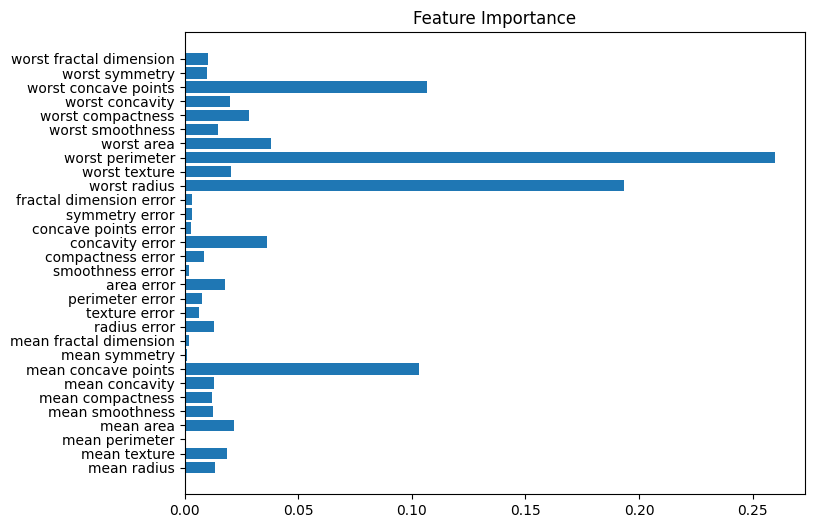

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.barh(X.columns, model.feature_importances_)
plt.title("Feature Importance")
plt.show()